In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns


In [22]:
import pandas as pd
import re

# Nombres de columnas corregidos manualmente basados en la inspección
columnas_corregidas = [
    'ANIO', 'MES', 'FEMICIDIO', 'FEMICIDIO_NO_INTIMO', 'SUICIDIO_FEMICIDA',
    'VIOLACION_CON_HOMICIDIO', 'ROBO_CON_HOMICIDIO', 'AUXILIO_AL_SUICIDIO', 'OTROS_HOMICIDIOS',
    'TORTURA_O_APREMIOS_ILEGITIMOS_CON_VIOLACION', 'ROBO_CON_VIOLACION', 'OTRAS_VIOLACIONES',
    'ABUSOS_SEXUALES', 'OTROS_DELITOS_SEXUALES', 'ROBOS_CON_VIOLENCIA_O_INTIMIDACION',
    'ROBO_VIOLENTO_DE_VEHICULO_MOTORIZADO', 'VIOLENCIA_INTRAFAMILIAR_A_MUJER',
    'VIOLENCIA_INTRAFAMILIAR_A_NINO_O_NINA', 'VIOLENCIA_INTRAFAMILIAR_A_ADULTO_MAYOR',
    'VIOLENCIA_INTRAFAMILIAR_A_HOMBRE', 'VIOLENCIA_INTRAFAMILIAR_NO_CLASIFICADA',
    'TRAFICO_DE_SUSTANCIAS', 'MICROTRAFICO_DE_SUSTANCIAS', 'ELABORACION_O_PRODUCCION_DE_SUSTANCIAS',
    'OTRAS_INFRACCIONES_A_LA_LEY_DE_DROGAS', 'DISPARO_INJUSTIFICADO',
    'PORTE_POSESION_DE_ARMAS_O_EXPLOSIVOS', 'OTRAS_INFRACCIONES_A_LA_LEY_DE_ARMAS',
    'ROBO_EN_LUGAR_HABITADO', 'ROBOS_EN_LUGAR_NO_HABITADO', 'ROBO_DE_VEHICULO_MOTORIZADO',
    'ROBO_DE_OBJETOS_DE_O_DESDE_VEHICULO', 'ANIMALES_SUELTOS_EN_LA_VIA_PUBLICA',
    'COMERCIO_ILEGAL', 'OFENSAS_AL_PUDOR', 'OTRAS_INCIVILIDADES', 'ABIGEATO', 'ROBO_FRUSTRADO',
    'OTROS_DELITOS_O_FALTAS'
]

# Leer el archivo ignorando los nombres de columnas originales
df = pd.read_csv(
    'delitos_puerto_montt_2024.csv',
    sep=';',
    encoding='latin1',
    decimal=',',
    thousands='.',
    header=0,  # Usa la primera línea como encabezado pero lo reemplazaremos
    names=columnas_corregidas  # Sobreescribe con nombres correctos
)

# Limpieza adicional de datos
df['ANIO'] = df['ANIO'].ffill().astype(int)

# Mostrar los datos
pd.set_option('display.max_columns', None)
print("Datos cargados correctamente:")
print(df.head())
print("\nInformación del DataFrame:")
print(df.info())

Datos cargados correctamente:
   ANIO  MES  FEMICIDIO  FEMICIDIO_NO_INTIMO  SUICIDIO_FEMICIDA  VIOLACION_CON_HOMICIDIO  ROBO_CON_HOMICIDIO  AUXILIO_AL_SUICIDIO  OTROS_HOMICIDIOS  TORTURA_O_APREMIOS_ILEGITIMOS_CON_VIOLACION  ROBO_CON_VIOLACION  OTRAS_VIOLACIONES  ABUSOS_SEXUALES  OTROS_DELITOS_SEXUALES  ROBOS_CON_VIOLENCIA_O_INTIMIDACION  ROBO_VIOLENTO_DE_VEHICULO_MOTORIZADO  VIOLENCIA_INTRAFAMILIAR_A_MUJER  VIOLENCIA_INTRAFAMILIAR_A_NINO_O_NINA  VIOLENCIA_INTRAFAMILIAR_A_ADULTO_MAYOR  VIOLENCIA_INTRAFAMILIAR_A_HOMBRE  VIOLENCIA_INTRAFAMILIAR_NO_CLASIFICADA  TRAFICO_DE_SUSTANCIAS  MICROTRAFICO_DE_SUSTANCIAS  ELABORACION_O_PRODUCCION_DE_SUSTANCIAS  OTRAS_INFRACCIONES_A_LA_LEY_DE_DROGAS  DISPARO_INJUSTIFICADO  PORTE_POSESION_DE_ARMAS_O_EXPLOSIVOS  OTRAS_INFRACCIONES_A_LA_LEY_DE_ARMAS  ROBO_EN_LUGAR_HABITADO  ROBOS_EN_LUGAR_NO_HABITADO  ROBO_DE_VEHICULO_MOTORIZADO  ROBO_DE_OBJETOS_DE_O_DESDE_VEHICULO  ANIMALES_SUELTOS_EN_LA_VIA_PUBLICA  COMERCIO_ILEGAL  OFENSAS_AL_PUDOR  OTRAS_INCIVILIDADE

In [7]:
# Entradas: todo menos la última fila (porque no tenemos y real de esa)
#print(df.columns.tolist())

X = df.drop(['AO', 'MES'], axis=1)[:-1]
y = df.drop(['AO', 'MES'], axis=1).shift(-1)[:-1]

['AO', 'MES', '??Femicidio', '??Femicidio no ntimo', '??Suicidio femicida', '??Violacin con homicidio', '??Robo con homicidio', '??Auxilio al suicidio', '??Otros homicidios', '??Tortura o apremios ilegtimos con violacin', '??Robo con violacin', '??Otras violaciones', '??Abusos sexuales', '??Otros delitos sexuales', '??Robos con violencia o intimidacin', '??Robo violento de vehculo motorizado', '??Violencia intrafamiliar a mujer', '??Violencia intrafamiliar a nio o nia', '??Violencia intrafamiliar a adulto mayor', '??Violencia intrafamiliar a hombre', '??Violencia intrafamiliar no clasificada', '??Trfico de sustancias', '??Microtrfico de sustancias', '??Elaboracin o produccin de sustancias', '??Otras infracciones a la ley de drogas', '??Disparo injustificado', '??Porte / posesin de armas o explosivos', '??Otras infracciones a la ley de armas', '??Robo en lugar habitado', '??Robos en lugar no habitado', '??Robo de vehculo motorizado', '??Robo de objetos de o desde vehculo', '??Animales s

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [9]:
model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [10]:
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print("Error cuadrático medio:", mse)


Error cuadrático medio: 6909.829092596727


In [12]:
# Último mes del dataset
last_month = df.drop(['AO', 'MES'], axis=1).iloc[[-1]]

# Predicción de delitos para el mes siguiente
next_month_prediction = model.predict(last_month)
print("Predicción de delitos para el mes siguiente:")
print(pd.Series(next_month_prediction.flatten(), index=X.columns).sort_values(ascending=False).head(5))


Predicción de delitos para el mes siguiente:
??Violencia intrafamiliar a mujer      790.312797
??Otras incivilidades                  242.685972
??Robo en lugar habitado               233.850073
??Violencia intrafamiliar a hombre     159.424701
??Robos con violencia o intimidacin    105.666904
dtype: float64


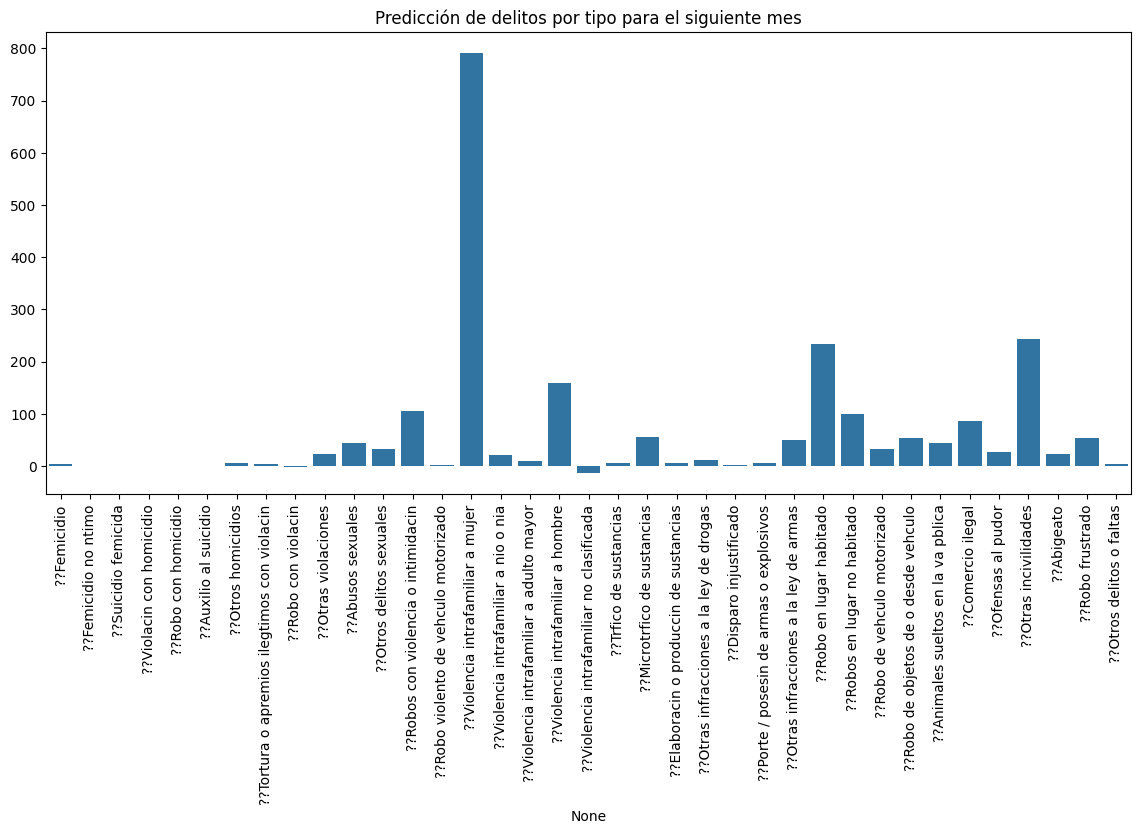

In [13]:
# Comparar predicción vs. valor real para algunas variables
plt.figure(figsize=(14, 6))
sns.barplot(x=X.columns, y=next_month_prediction.flatten())
plt.xticks(rotation=90)
plt.title("Predicción de delitos por tipo para el siguiente mes")
plt.show()
